<a href="https://colab.research.google.com/github/Esrar15/Gait-event-detection-with-random-forest/blob/main/Gait_event_detection_full_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
import glob

In [ ]:
zip_path = "/content/drive/MyDrive/IMU-Based_Walking_Data.zip"
extract_dir = "/content/walking_data"
with zipfile.ZipFile(zip_path, 'r') as f:
  f.extractall(extract_dir)

In [ ]:
files = sorted(glob.glob(f"{extract_dir}/**/*.csv", recursive=True))
print(len(files), "files")
for p in files[:10]:
    print(p)

82 files
/content/walking_data/P01/CU_AFO_001_0523.csv
/content/walking_data/P01/CU_AFO_001_0524.csv
/content/walking_data/P01/CU_AFO_001_1102.csv
/content/walking_data/P01/CU_AFO_001_1103.csv
/content/walking_data/P01/CU_AFO_001_1104.csv
/content/walking_data/P01/CU_AFO_001_1105.csv
/content/walking_data/P01/CU_AFO_001_1106.csv
/content/walking_data/P01/CU_AFO_001_1107.csv
/content/walking_data/P02/CU_AFO_002_0404.csv
/content/walking_data/P02/CU_AFO_002_0405.csv


In [ ]:
df = pd.read_csv(files[0])
print(df.shape)
print(df.head(3))
print(df.iloc[:, -1].value_counts())          # last column = gait events

(1022, 68)
    Time(s)  S1-AccX  S1-AccY  S1-AccZ  S1-GyroX  S1-GyroY  S1-GyroZ  \
0  0.006000      988       21      -76        38        48       -87   
1  0.026000      974       36      -73        -8        46       -75   
2  0.046001      973       22      -60       -69        43       -65   

   S1-LinAccX  S1-LinAccY  S1-LinAccZ  ...  S4-QuatZ  S4-Temp  S4-CalibStat  \
0           0          23         -16  ...      -908       32            52   
1          -2          28          -6  ...      -915       32            52   
2          -8          14           2  ...      -921       32            52   

   RKnee_X(flexion)   RKnee_Y   RKnee_Z  RHFTBA_X(flexion)  RHFTBA_Y  \
0          1.463618 -0.347371 -3.231337           3.521845  0.435740   
1          1.423259 -0.354190 -3.362656           3.548100  0.259552   
2          1.385917 -0.359223 -3.485429           3.583927  0.152829   

   RHFTBA_Z(inversion)  R_GaitEvents(TO:1, HS:2)  
0             1.946604                     

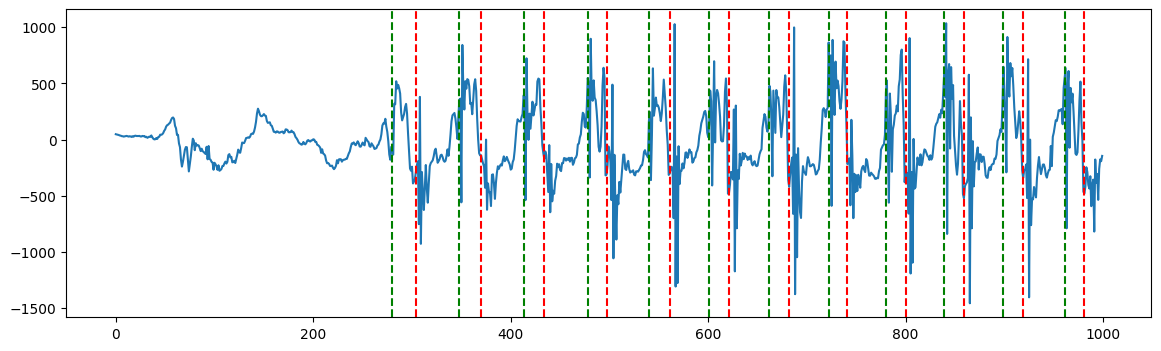

approx sampling rate: 49.99999999999885


In [ ]:
t = df.iloc[:, 0].values
gyro_y = df.iloc[:, 5].values                 # S1 (shank) gyro, adjust axis if needed
lab = df.iloc[:, 67].values

plt.figure(figsize=(14,4))
plt.plot(gyro_y[:1000])
for i in np.where(lab[:1000]==1)[0]: plt.axvline(i, color='g', ls='--')   # toe off
for i in np.where(lab[:1000]==2)[0]: plt.axvline(i, color='r', ls='--')   # heel strike
plt.show()
print("approx sampling rate:", 1/np.median(np.diff(t)))

In [ ]:
rows = []
for p in files:
    d = pd.read_csv(p)
    lab = d.iloc[:, -1]
    t = d.iloc[:, 0].values
    rows.append(dict(
        participant=p.split('/')[-2],
        file=os.path.basename(p),
        n_rows=len(d),
        n_cols=d.shape[1],
        fs=round(1/np.median(np.diff(t)), 1),
        toe_off=int((lab==1).sum()),
        heel_strike=int((lab==2).sum()),
        nan=int(d.isna().sum().sum()),
    ))

summary = pd.DataFrame(rows)
pd.set_option('display.width', 200); pd.set_option('display.max_rows', None)
print(summary)
print(summary.groupby('participant')[['n_rows','toe_off','heel_strike']].sum())

   participant                 file  n_rows  n_cols    fs  toe_off  heel_strike  nan
0          P01  CU_AFO_001_0523.csv    1022      68  50.0       12           12    0
1          P01  CU_AFO_001_0524.csv    2925      68  50.0       47           46    0
2          P01  CU_AFO_001_1102.csv    1399      68  50.0       20           20    0
3          P01  CU_AFO_001_1103.csv    2984      68  50.0       46           45    0
4          P01  CU_AFO_001_1104.csv    1364      68  50.0       23           23    0
5          P01  CU_AFO_001_1105.csv    3046      68  50.0       52           52    0
6          P01  CU_AFO_001_1106.csv    1448      68  50.0       17           17    0
7          P01  CU_AFO_001_1107.csv    3079      68  50.0       39           39    0
8          P02  CU_AFO_002_0404.csv    1009      68  50.0       11            7    0
9          P02  CU_AFO_002_0405.csv    3057      68  50.0       48           43    0
10         P02  CU_AFO_002_0504.csv    1182      68  50.0       1

In [ ]:
def event_gaps(path):
    df = pd.read_csv(path)                      # header row is present
    y = pd.to_numeric(df.iloc[:, 67], errors="coerce").values
    to = np.where(y == 1)[0]
    hs = np.where(y == 2)[0]
    return np.diff(to), np.diff(hs)             # in samples; x20 ms

In [ ]:
for i in range(df.shape[1]):         #finding the real label column
    u = df.iloc[:, i].nunique()
    if u <= 5:
        print(i, df.iloc[:, i].unique())

14 [32]
15 [48]
29 [33]
30 [52]
44 [29 28]
45 [52]
59 [32 33]
60 [52]
67 [0 1 2]


In [ ]:
path = "/content/walking_data/P01/CU_AFO_001_0523.csv"   # adjusted to my Colab path, e.g. /content/...

to_gaps, hs_gaps = event_gaps(path)

print("Toe-off gaps (samples):", to_gaps)
print("Heel-strike gaps (samples):", hs_gaps)

# Summary in samples and ms (1 sample = 20 ms)
for name, g in [("Toe-off", to_gaps), ("Heel-strike", hs_gaps)]:
    print(f"{name}: n={len(g)}, min={g.min()}, median={np.median(g)}, "
          f"max={g.max()}, median={np.median(g)*20:.0f} ms")

Toe-off gaps (samples): [68 65 65 62 61 61 60 58 59 60 62]
Heel-strike gaps (samples): [66 64 64 63 60 61 59 59 59 60 62]
Toe-off: n=11, min=58, median=61.0, max=68, median=1220 ms
Heel-strike: n=11, min=59, median=61.0, max=66, median=1220 ms


In [ ]:
#Excluding some files

def break_points(path):
    y = pd.to_numeric(pd.read_csv(path).iloc[:, 67], errors="coerce").values
    idx = np.where((y == 1) | (y == 2))[0]
    ev = y[idx]
    bad = np.where(ev[1:] == ev[:-1])[0]
    return idx[bad], idx[bad + 1]   # sample positions of the repeated labels

In [ ]:
#starting the training

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = "/content/walking_data"
TRAIN_P = ["P01","P02","P04","P05","P06","P07","P08"]
VAL_P = ["P09"]
TEST_P = ["P10","P11"]

In [ ]:
from scipy.ndimage import binary_dilation
from scipy.signal import find_peaks

In [ ]:
def add_context(df, feat_cols, w=5):
    out = [df[feat_cols]]
    for k in (-w, -2, 2, w):                # leads and lags
        out.append(df[feat_cols].shift(k).add_suffix(f"_s{k}"))
    out.append(df[feat_cols].diff().add_suffix("_d"))
    out.append(df[feat_cols].rolling(2*w+1, center=True).std().add_suffix("_std"))
    return pd.concat(out, axis=1)

In [ ]:
def soft_label(y, k=3):
    out = np.zeros_like(y)
    for c in (1, 2):
        out[binary_dilation(y == c, structure=np.ones(2*k+1))] = c
    return out

def match(pred, true, tol=3):
    tp, errs, used = 0, [], set()
    for t in true:
        c = [p for p in pred if abs(p-t) <= tol and p not in used]
        if c:
            p = min(c, key=lambda p: abs(p-t)); used.add(p); tp += 1; errs.append((p-t)*20)
    return tp, len(pred)-tp, len(true)-tp, errs

In [ ]:
#checking if any column name without text
f = glob.glob(f"{ROOT}/P07/*.csv")[0]
df = pd.read_csv(f, header=None)
print(df.iloc[:3, :6])      # is row 0 text like "Time", "Acc_X"?
print(df.dtypes.value_counts())

         0        1        2        3         4         5
0  Time(s)  S1-AccX  S1-AccY  S1-AccZ  S1-GyroX  S1-GyroY
1    0.005      971      -92     -235        -5       -12
2    0.025      946      -61     -232        -2       -10
object    68
Name: count, dtype: int64


In [ ]:
BAD_FILES = set()   # add filenames here after checking with break_points()

def load_files(participants, k=3):
    out = []
    for p in participants:
        for f in sorted(glob.glob(f"{ROOT}/{p}/*.csv")):
            if os.path.basename(f) in BAD_FILES: continue
            df = pd.read_csv(f).apply(pd.to_numeric, errors="coerce")
            raw = df.iloc[:, 67].fillna(0).astype(int).values
            feats = df.iloc[:, :67].dropna(axis=1, how="all")
            feats.columns = [f"c{i}" for i in range(feats.shape[1])]
            Xf = add_context(feats, list(feats.columns)).fillna(0)
            out.append((Xf, raw, soft_label(raw, k)))
    return out

train_files = load_files(TRAIN_P)
val_files   = load_files(VAL_P)

Xtr = pd.concat([x for x, _, _ in train_files]).reset_index(drop=True)
ytr = np.concatenate([s for _, _, s in train_files])

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=1,
    class_weight="balanced_subsample", n_jobs=-1, random_state=42)
rf.fit(Xtr, ytr)

RandomForestClassifier(class_weight='balanced_subsample', n_estimators=200,
                       n_jobs=-1, random_state=42)

In [ ]:
def evaluate(files, height=0.3, tol=3):
    res = {1: [0,0,0,[]], 2: [0,0,0,[]]}   # TP, FP, FN, errors
    for Xf, raw, _ in files:
        proba = rf.predict_proba(Xf)
        for c in (1, 2):
            pred = find_peaks(proba[:, c], height=height, distance=30)[0]
            true = np.where(raw == c)[0]
            tp, fp, fn, errs = match(pred, true, tol)
            res[c][0]+=tp; res[c][1]+=fp; res[c][2]+=fn; res[c][3]+=errs
    for c, name in [(1,"toe_off"), (2,"heel_strike")]:
        tp, fp, fn, errs = res[c]
        pr = tp/(tp+fp+1e-9); rc = tp/(tp+fn+1e-9)
        print(f"{name}: P={pr:.2f} R={rc:.2f} F1={2*pr*rc/(pr+rc+1e-9):.2f} "
              f"mean |err|={np.mean(np.abs(errs)) if errs else float('nan'):.0f} ms")

for h in (0.15, 0.2, 0.3, 0.4):
    print("height =", h); evaluate(val_files, height=h)

height = 0.15
toe_off: P=1.00 R=1.00 F1=1.00 mean |err|=13 ms
heel_strike: P=0.99 R=1.00 F1=0.99 mean |err|=21 ms
height = 0.2
toe_off: P=1.00 R=1.00 F1=1.00 mean |err|=13 ms
heel_strike: P=1.00 R=0.99 F1=0.99 mean |err|=21 ms
height = 0.3
toe_off: P=1.00 R=1.00 F1=1.00 mean |err|=13 ms
heel_strike: P=1.00 R=0.99 F1=0.99 mean |err|=21 ms
height = 0.4
toe_off: P=1.00 R=1.00 F1=1.00 mean |err|=13 ms
heel_strike: P=1.00 R=0.99 F1=0.99 mean |err|=21 ms


In [ ]:
test_files = load_files(TEST_P)
evaluate(test_files, height=0.3)   # use your best height from Cell 5

toe_off: P=1.00 R=1.00 F1=1.00 mean |err|=15 ms
heel_strike: P=0.99 R=0.99 F1=0.99 mean |err|=17 ms


[[  0   1   5]
 [  0 632   0]
 [  4   0 623]]


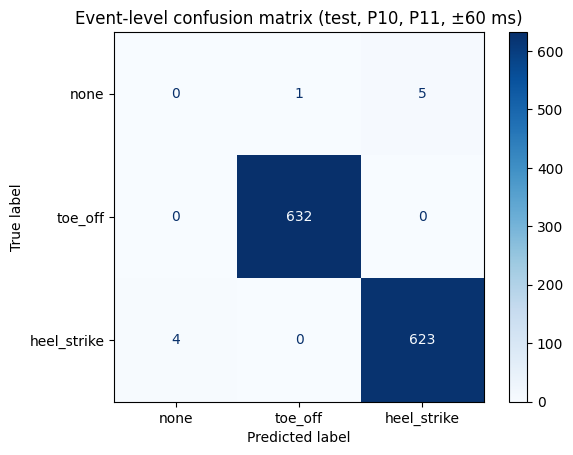

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

def event_confusion(files, height=0.3, tol=3):
    # rows = true (none, TO, HS), cols = predicted (none, TO, HS)
    cm = np.zeros((3, 3), dtype=int)
    for Xf, raw, _ in files:
        proba = rf.predict_proba(Xf)
        for c in (1, 2):
            pred = find_peaks(proba[:, c], height=height, distance=30)[0]
            true = np.where(raw == c)[0]
            tp, fp, fn, _ = match(pred, true, tol)
            cm[c, c] += tp      # correct detection
            cm[c, 0] += fn      # missed event
            cm[0, c] += fp      # false alarm
    return cm

cm = event_confusion(test_files, height=0.3)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["none", "toe_off", "heel_strike"]).plot(cmap="Blues", values_format="d")
plt.title("Event-level confusion matrix (test, P10, P11, ±60 ms)")
plt.show()